# 06 Corruption ladder

Real Kaggle data turned out to be clean in the dimensions a matcher is most sensitive to
(D1, D2, D4 are empty at L0 for both C-doc datasets). So those dimensions are introduced
deliberately, one per level, with ground truth preserved through recorded rename maps.

**Two modes, and the report must say which one a table shows:**

- *attribution* — each level applies only its own operators to the original frame. Later
  levels are not necessarily worse, because the corruptions do not stack. Answers "which
  dimension breaks which matcher signal".
- *cumulative* — levels 0..n applied in order. Answers "how does recovery decay as dirt
  accumulates".

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

In [2]:
from swsn.corrupt import load_ladder, level_order, parse_level

ladder = load_ladder("../corruption/ladder.yaml")
for level in level_order(ladder):
    specs = parse_level(ladder, level)
    print(f"{level}: {specs[0].dimension if specs else '—'}  {[s.id for s in specs]}")

L0: —  []
L1: D1  ['rename_synonym', 'rename_abbreviate', 'rename_translate', 'append_unit_to_header', 'autogenerated_name', 'duplicate_header', 'reorder_columns', 'add_spurious_column']
L2: D4  ['date_reformat', 'number_thousand_separator', 'number_decimal_comma', 'currency_symbol', 'floatify', 'zero_pad', 'id_prefix']
L3: D3  ['sentinel_null', 'mixed_type_in_column', 'whitespace_pad', 'unicode_variants', 'unit_in_value', 'case_variation_values']
L4: D5  ['synonym_substitute', 'translate_values', 'category_recode']


## The degradation curve

In [3]:
cumulative = pd.read_csv("../evaluation/results_cumulative.csv")
from swsn.run_benchmark import summary
summary(cumulative).to_string()

'matcher   coma  cupid  distribution_based  jaccard  similarity_flooding\nlevel                                                                  \nL0       0.958  0.847               0.648    0.875                0.958\nL1       0.431  0.292               0.537    0.708                0.833\nL2       0.431  0.208               0.292    0.403                0.750\nL3       0.431  0.292               0.283    0.403                0.722\nL4       0.431  0.292               0.250    0.403                0.722'

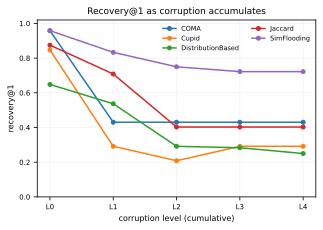

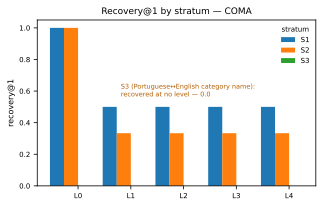

In [4]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
from IPython.display import SVG, display
display(SVG(filename="../reports/figures/f3_degradation.svg"))
display(SVG(filename="../reports/figures/f4_strata_coma.svg"))

## What it shows

Header noise (L1) costs more than every other dimension combined. COMA drops from 0.958 to
0.431 the moment columns are renamed, abbreviated and translated, and the value-format
levels after it add nothing further — once the names are gone, they were the only signal
COMA had left that mattered.

And by stratum: **the S3 correspondence — the one genuine cross-lingual pair — is recovered
by no matcher at any level, at 0.0 throughout**, while S1 sits at 1.0 until L1.

That 0.0 is the case for the project's extension. Everything else recovers; this does not.

## Reproducing

```bash
make bench      # evaluation/results_attribution.csv + results_cumulative.csv
make figures    # reports/figures/*.pdf + *.svg
```